## 1. Pipeline

Load the data and run the four pipeline functions:

- `load_data`: reads the CSV into a pandas DataFrame
- `build_features`: builds `X` (2D NumPy array, 9 features) and `y` (1D array of labels 0, 1, 2)
- `split_data`: random and reproducible 80/20 split into train and test
- `standardize`: scales every feature with the mean and standard deviation of the training set

In [4]:
import matplotlib.pyplot as plt
import penguin_pipeline as pp

df = pp.load_data("penguins.csv")
X, y = pp.build_features(df)
X_train, X_test, y_train , y_test = pp.split_data(X, y)
X_train_scaled, X_test_scaled, mu, std = pp.standardize(X_train, X_test)

print(X.shape, y.shape)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
print(X_train_scaled.mean(axis=0).round(3), X_train_scaled.std(axis=0).round(3))
print(mu[3].round(2))

(333, 9) (333,)
(266, 9) (67, 9) (266,) (67,)
[-0.  0.  0.  0. -0.  0.  0. -0.  0.] [1. 1. 1. 1. 1. 1. 1. 1. 1.]
4238.25


## 2. Building a scatter graph
Comparing the beak and the flipper length

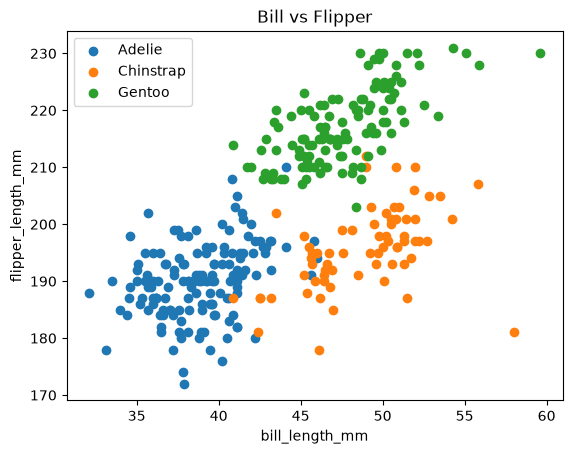

In [5]:
names = ["Adelie", "Chinstrap", "Gentoo"]
for value in range(3):
    mask = y == value
    plt.scatter(X[mask,0], X[mask,2], label=names[value])
plt.xlabel("bill_length_mm")
plt.ylabel("flipper_length_mm")
plt.title("Bill vs Flipper")
plt.legend()
plt.show()

## 3. Creating Histograms of Penguin Weights

We will use the data from `X_train` (without standardization) for the first histogram, and the data from `X_train_scaled` (standardized) for the second one.

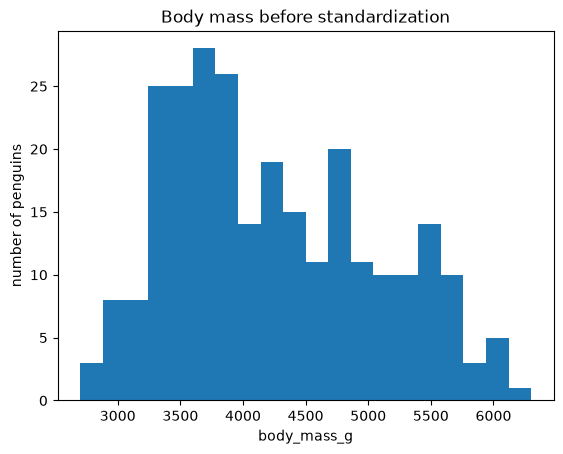

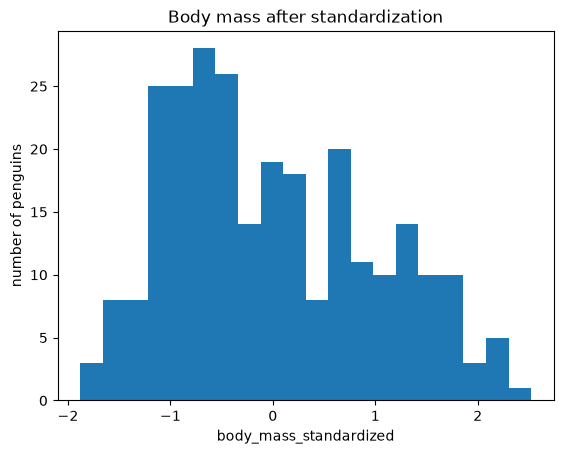

In [6]:
plt.hist(X_train[:,3], bins=20)
plt.xlabel("body_mass_g")
plt.ylabel("number of penguins")
plt.title("Body mass before standardization")
plt.show()

plt.hist(X_train_scaled[:,3], bins=20)
plt.xlabel("body_mass_standardized")
plt.ylabel("number of penguins")
plt.title("Body mass after standardization")
plt.show()